In [1]:
import numpy as np
import scipy
import scipy.linalg
import random
import math
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import qr, svd
from tqdm import tqdm
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

In [3]:
def initial(num):
    U = np.zeros((num,num//2),dtype=np.complex_)
    for i in range(num//2):
        U[2*i+1,i]=1+0*1j
    return U

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 

In [6]:
initial(6)

array([[0.+0.j, 0.+0.j, 0.+0.j],
       [1.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j]])

In [315]:
initial(4)

array([[0.+0.j, 0.+0.j],
       [1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j]])

In [4]:

def evolution(U_i,H,gamma,dt):
    D = np.dot(U_i,U_i.conjugate().T)
    nj= np.diag(D).real
    
    M=np.zeros((U_i.shape[0],U_i.shape[0]),dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i,i]=random.gauss(mu=0, sigma=np.sqrt(gamma*dt))/dt+gamma*(2*nj[i]-1)/2

    h = H+1j*M
    U = np.dot(scipy.linalg.expm(-1j*h*dt),U_i)
    
    return normalize(U),nj[0],nj[1]


    


In [29]:
U = initial(50)
t= np.arange(0,50,0.01)

for t in t:
    U,_,_ = evolution(U,H(50),0,0.05)

In [23]:
U = initial(50)

In [31]:
A =  U.conj().T @ U 
A

array([[ 1.00000000e+00+0.j,  6.93889390e-18+0.j, -2.77555756e-17+0.j,
        -1.73472348e-17+0.j, -1.38777878e-17+0.j, -2.62376926e-17+0.j,
         0.00000000e+00+0.j, -2.77555756e-17+0.j,  1.38777878e-17+0.j,
        -2.77555756e-17+0.j, -1.17093835e-17+0.j,  0.00000000e+00+0.j,
         2.08166817e-17+0.j, -6.93889390e-18+0.j, -1.38777878e-17+0.j,
         2.38524478e-17+0.j, -6.93889390e-17+0.j,  2.77555756e-17+0.j,
        -2.77555756e-17+0.j,  1.38777878e-17+0.j, -4.33680869e-18+0.j,
         0.00000000e+00+0.j, -1.73472348e-17+0.j,  8.32667268e-17+0.j,
         0.00000000e+00+0.j],
       [ 6.93889390e-18+0.j,  1.00000000e+00+0.j, -6.93889390e-18+0.j,
         2.77555756e-17+0.j, -6.93889390e-18+0.j,  6.93889390e-18+0.j,
        -4.03323208e-17+0.j, -2.77555756e-17+0.j, -2.77555756e-17+0.j,
        -1.38777878e-17+0.j, -4.16333634e-17+0.j,  1.21430643e-17+0.j,
         0.00000000e+00+0.j,  0.00000000e+00+0.j,  0.00000000e+00+0.j,
        -1.38777878e-17+0.j, -5.20417043e-18+0.

In [5]:
time = np.linspace(0,10,1000)
gamma = np.arange(0,1,0.1)
n_1= np.zeros((10,len(time)))
n_2= np.zeros((10,len(time)))



for i in tqdm(range(10)):
    U=initial(50)
    for t in range(len(time)):    
        U ,n_1[i,t],n_2[i,t]= evolution(U,H(50),0,0.01)
    



  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:21<00:00,  2.17s/it]


In [6]:
eigval,eigvec = np.linalg.eig(H(50))
site = np.eye(50)
neel = np.zeros(50)
neel[::2]=1


# Define time and initialize n1
time = np.linspace(0, 10, 1000)
ns = np.zeros( len(time), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 0])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1

for t in tqdm(range(len(time))):
    sum_result = 0
    
    # Precompute the exponential terms for the current time step
    # Use element-wise multiplication to compute the complex exponential
    for j in range(50):
        A = dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
        
        B = dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
        
        # Compute the exponential for each combination of alpha and beta
        exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
        
        # Sum over alpha and beta using vectorized numpy operations
        sum_result += np.sum(A[:, None] * B[None, :] * exp_term) * neel[j]
        
    ns[t] = sum_result

100%|██████████| 1000/1000 [00:05<00:00, 179.19it/s]


c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


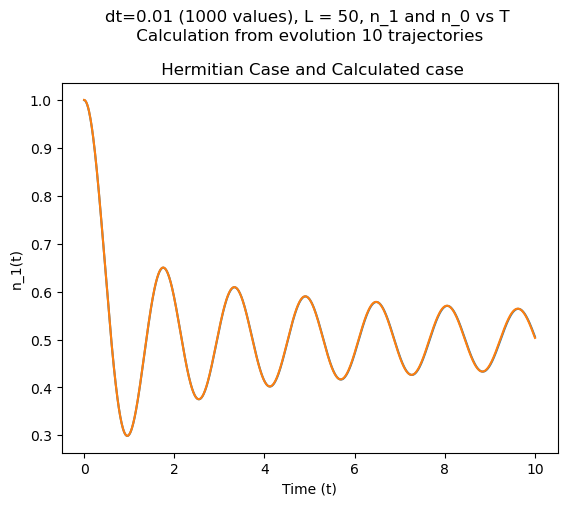

In [7]:
time = np.linspace(0,10,1000)
plt.plot(time,np.sum(n_2,axis = 0)/10)
plt.plot(time,ns)
plt.xlabel('Time (t)')
plt.ylabel('n_1(t)')
plt.title('dt=0.01 (1000 values), L = 50, n_1 and n_0 vs T \n Calculation from evolution 10 trajectories \n\n Hermitian Case and Calculated case')
plt.show()

In [289]:
import numpy as np
import scipy.linalg
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

# Define the evolution function
def evolution(U_i, H, gamma, dt):
    D = np.dot(U_i, U_i.conjugate().T)
    nj = np.diag(D).real  # Occupations at each site
    
    # Add noise term as before
    M = np.zeros((U_i.shape[0], U_i.shape[0]), dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i, i] = random.gauss(mu=0, sigma=np.sqrt(gamma * dt)) / dt + gamma * (2 * nj[i] - 1) / 2

    h = H + 1j * M  # Effective Hamiltonian with noise
    U = np.dot(scipy.linalg.expm(-1j * h * dt), U_i)
    
    # Density operator squared term for site 0
    density_matrix = np.dot(U, U.conjugate().T)
    n0_squared = density_matrix[0, 0].real ** 2  # Squared occupation for site 0

    # Two-body density correlation: ⟨c_0† c_0 c_0† c_0⟩
    density_correlation = density_matrix[0, 0] * density_matrix[0, 0].conj()

    return normalize(U), density_correlation.real

# Time parameters
time = np.linspace(0, 10, 1000)
dt = 0.01
gamma = 0.1  # Noise strength, adjustable

# Storage array for correlation calculations
density_corr = np.zeros((10, len(time)))

# Main loop for multiple runs
for i in tqdm(range(10)):
    U = initial(50)  # Initialize state
    for t in range(len(time)):    
        U, density_corr[i, t] = evolution(U, H(50), gamma, dt)

# Plot the time evolution of the density-density correlation for site 0
plt.figure(figsize=(8, 6))
plt.plot(time, np.mean(density_corr, axis=0), label=r'$\langle c_0^\dag c_0 c_0^\dag c_0 \rangle$')

plt.xlabel('Time (t)')
plt.ylabel('Density-Density Correlation')
plt.title('Density-Density Correlation for $c_0^\dag c_0 c_0^\dag c_0$')
plt.legend()
plt.show()


  0%|          | 0/10 [00:00<?, ?it/s]


TypeError: 'numpy.ndarray' object is not callable

In [45]:
def n_1n_2(traj,gamma,L):
    time = np.linspace(0,10,1000)
    
    n_1= np.zeros((traj,len(time)))
    n_2= np.zeros((traj,len(time)))



    for i in range(traj):
        U=initial(L)
        for t in tqdm(range(len(time))):    
            U ,n_1[i,t],n_2[i,t]= evolution(U,H(L),gamma,0.01)

    
    plt.plot(time,np.sum(n_1,axis = 0)/10)
    plt.plot(time,np.sum(n_2,axis = 0)/10)

    plt.xlabel('Time (t)')
    plt.ylabel('n_1(t)')
    plt.title(f'dt=0.01 (1000 values), for gamma = {gamma} L = {L}, n_1 and n_0 vs T \n Calculation from evolution {traj} trajectories')
    plt.show()
    
        

100%|██████████| 1000/1000 [00:02<00:00, 458.03it/s]


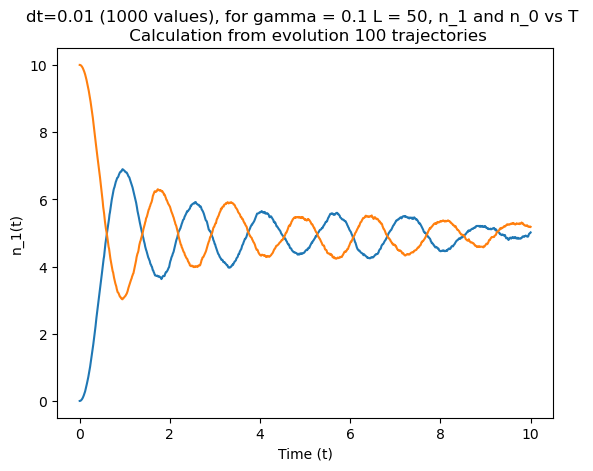

In [48]:
gamma = np.arange(0,1,0.1)

100%|██████████| 1000/1000 [00:02<00:00, 495.58it/s]


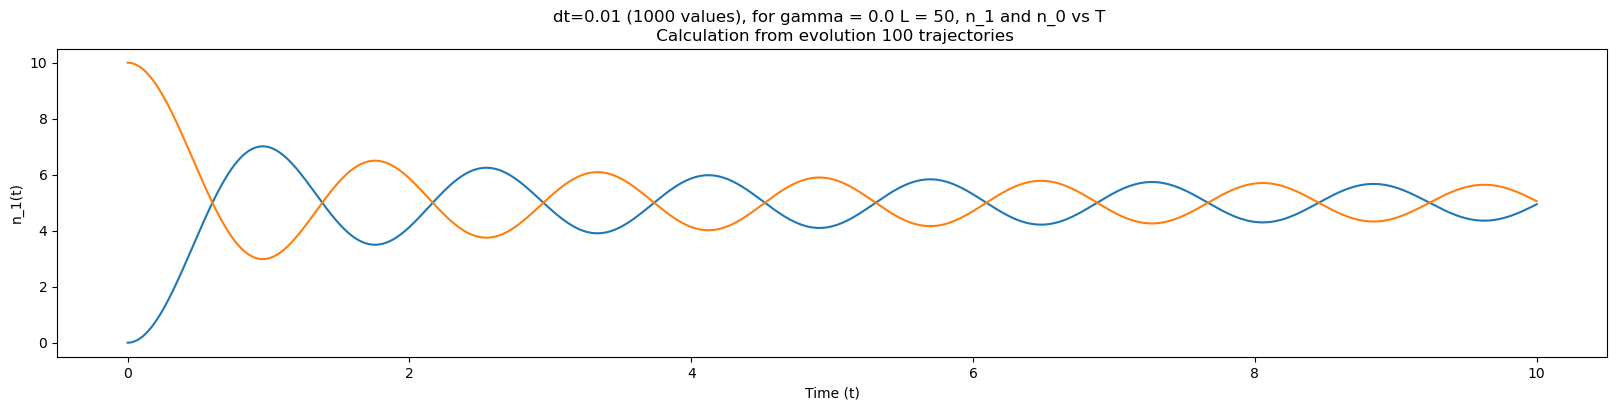

100%|██████████| 1000/1000 [00:04<00:00, 201.90it/s]


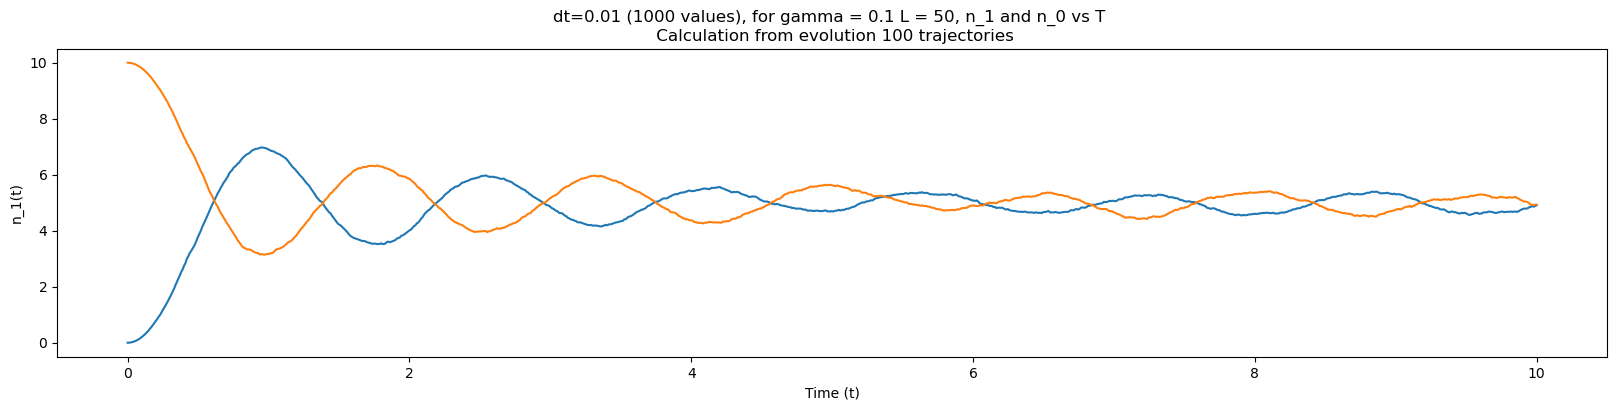

100%|██████████| 1000/1000 [00:02<00:00, 459.85it/s]


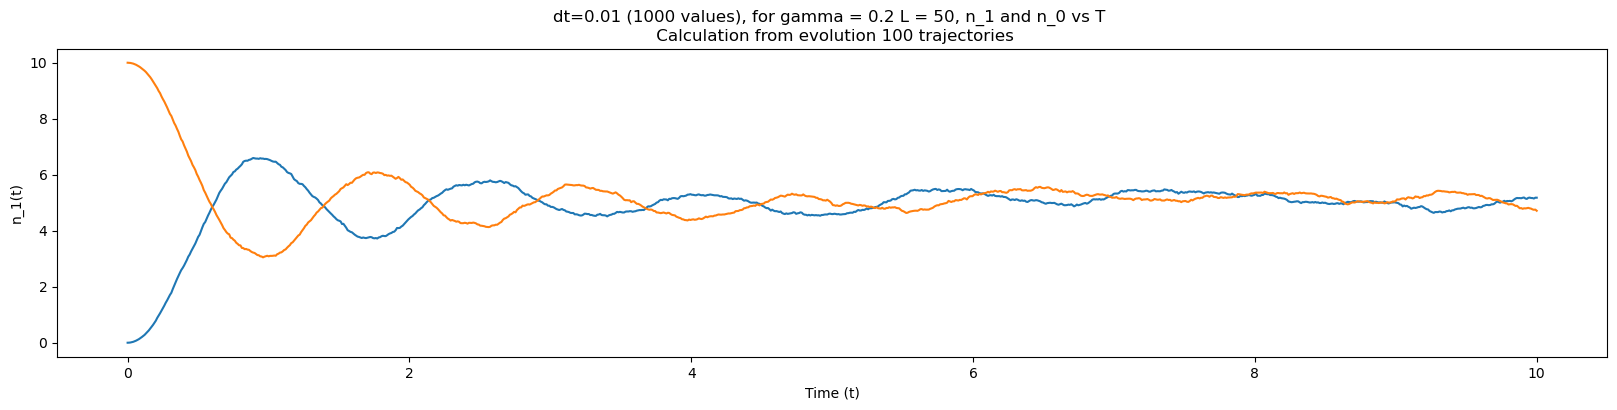

100%|██████████| 1000/1000 [00:02<00:00, 379.72it/s]


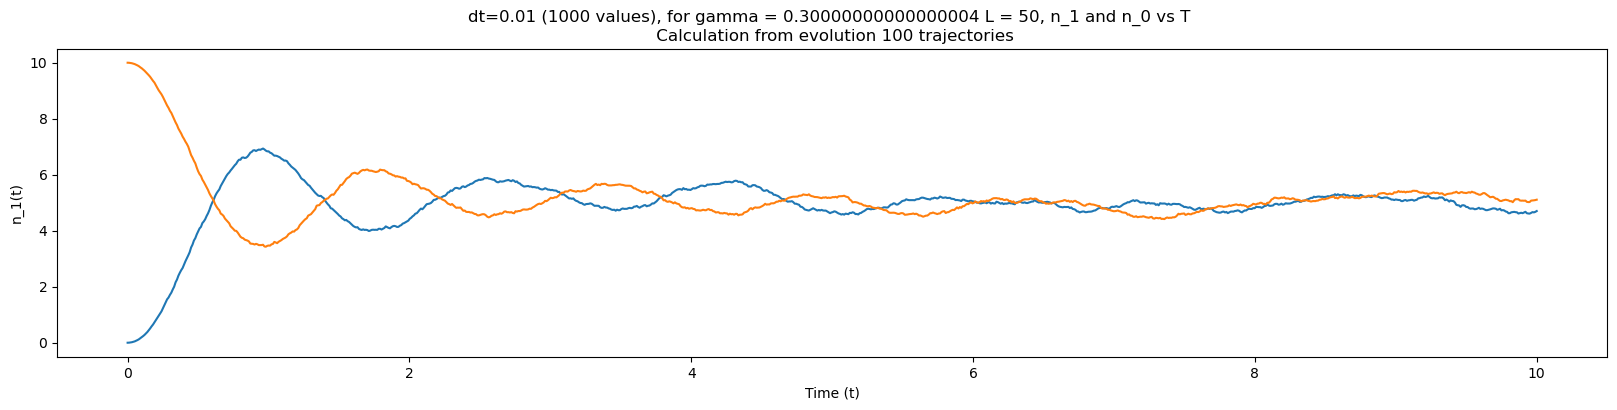

100%|██████████| 1000/1000 [00:02<00:00, 384.56it/s]


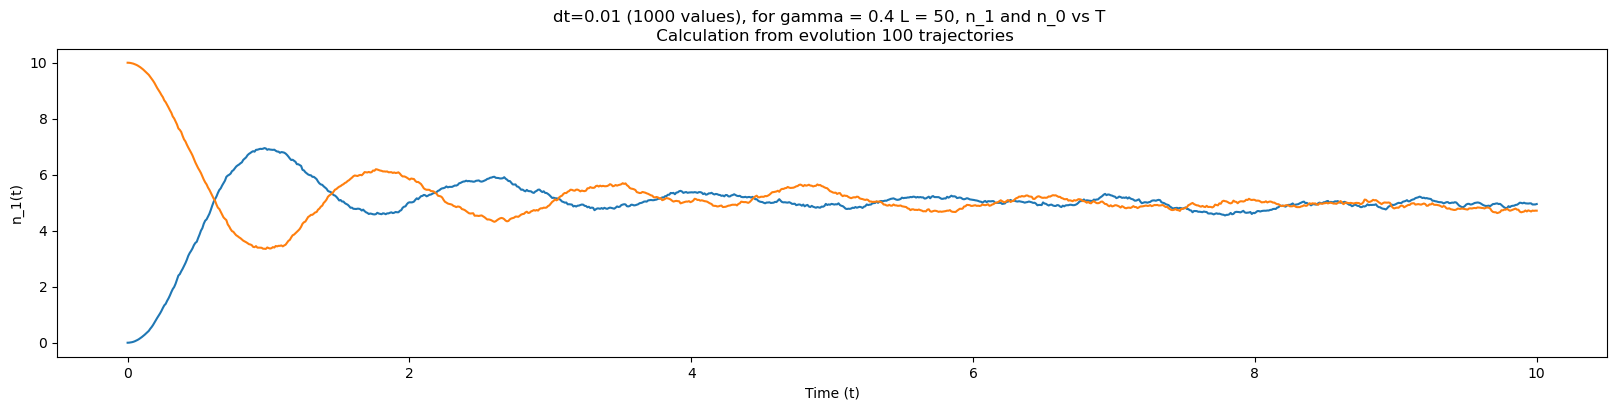

100%|██████████| 1000/1000 [00:02<00:00, 498.39it/s]


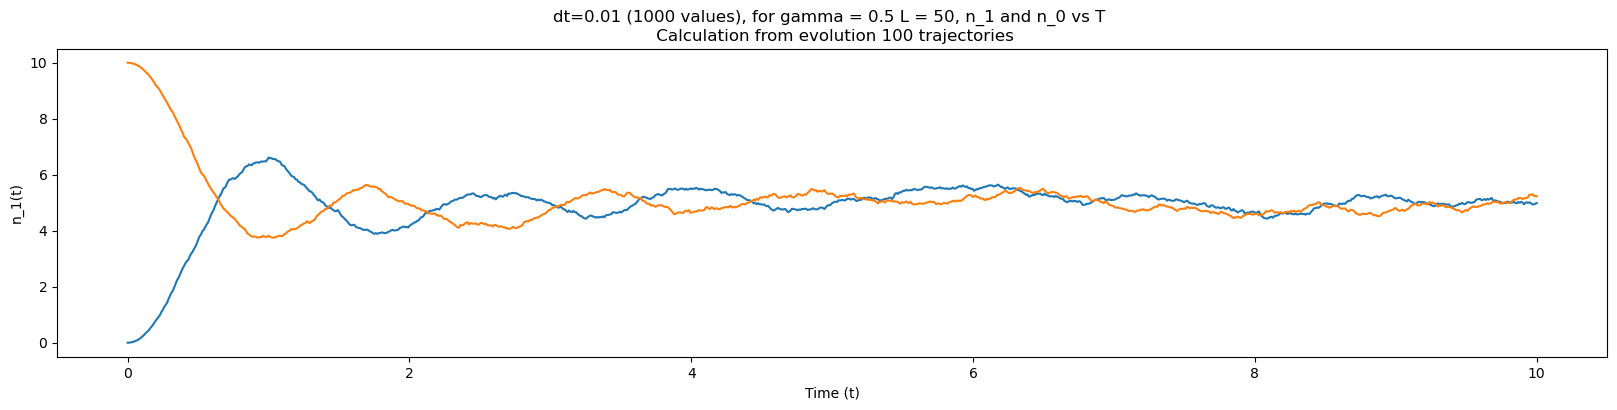

100%|██████████| 1000/1000 [00:02<00:00, 491.88it/s]


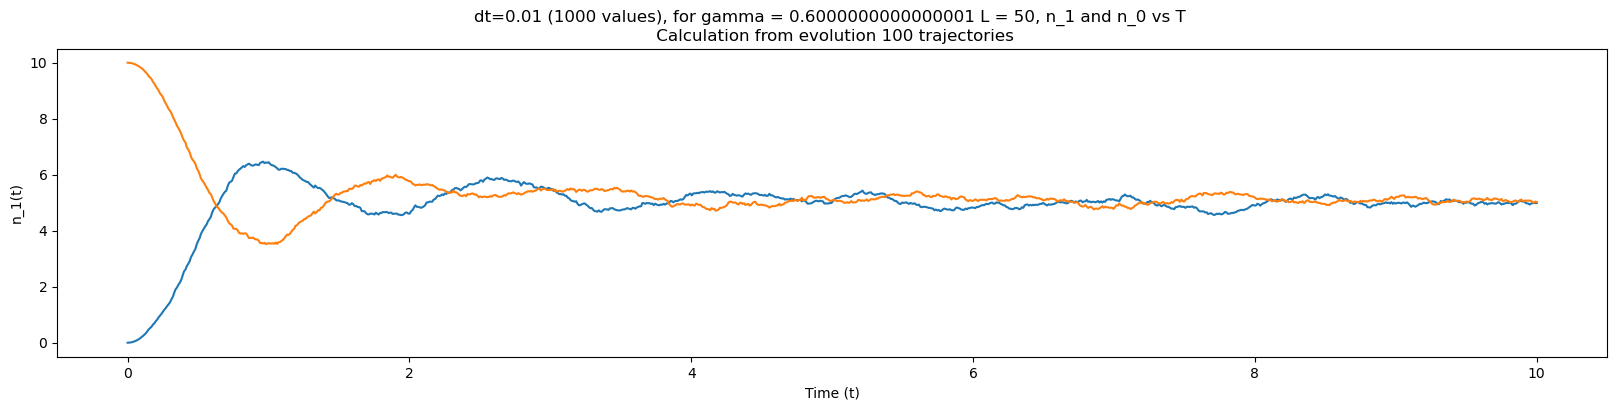

100%|██████████| 1000/1000 [00:02<00:00, 487.67it/s]


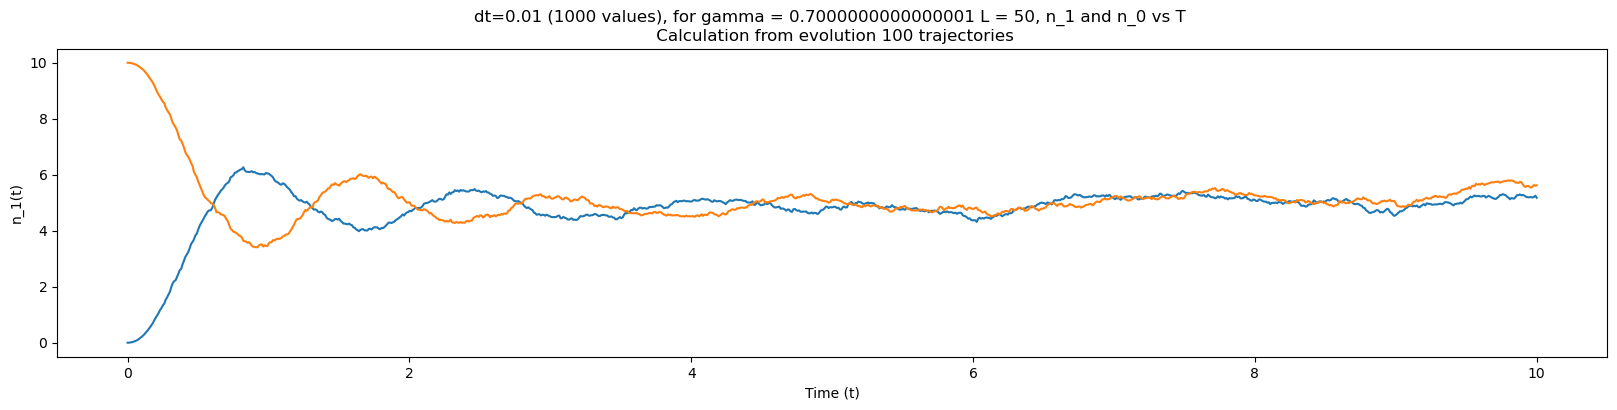

100%|██████████| 1000/1000 [00:02<00:00, 465.73it/s]


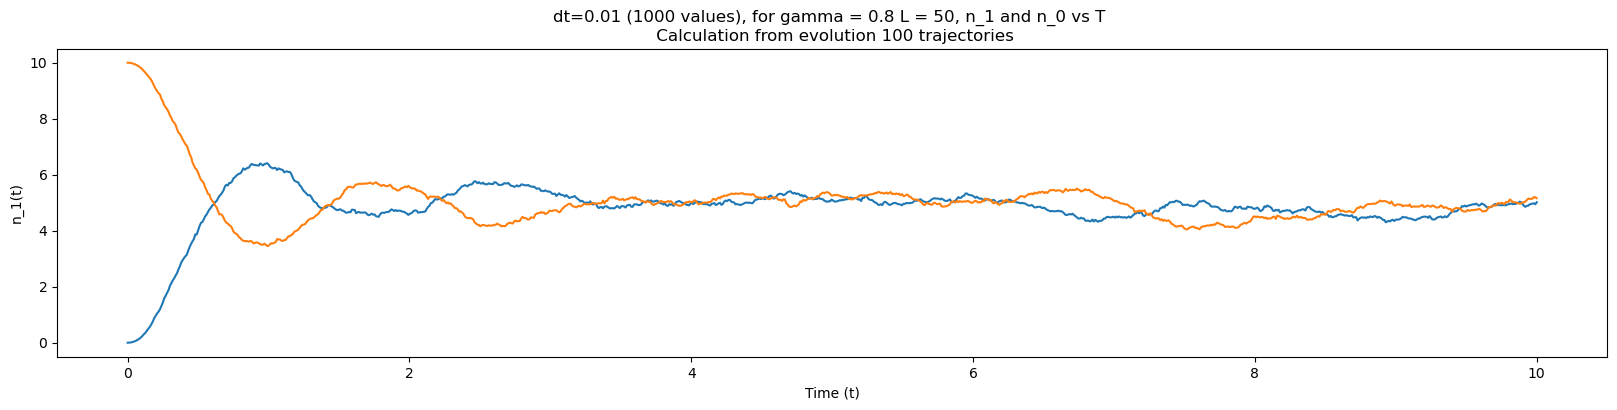

100%|██████████| 1000/1000 [00:02<00:00, 466.35it/s]


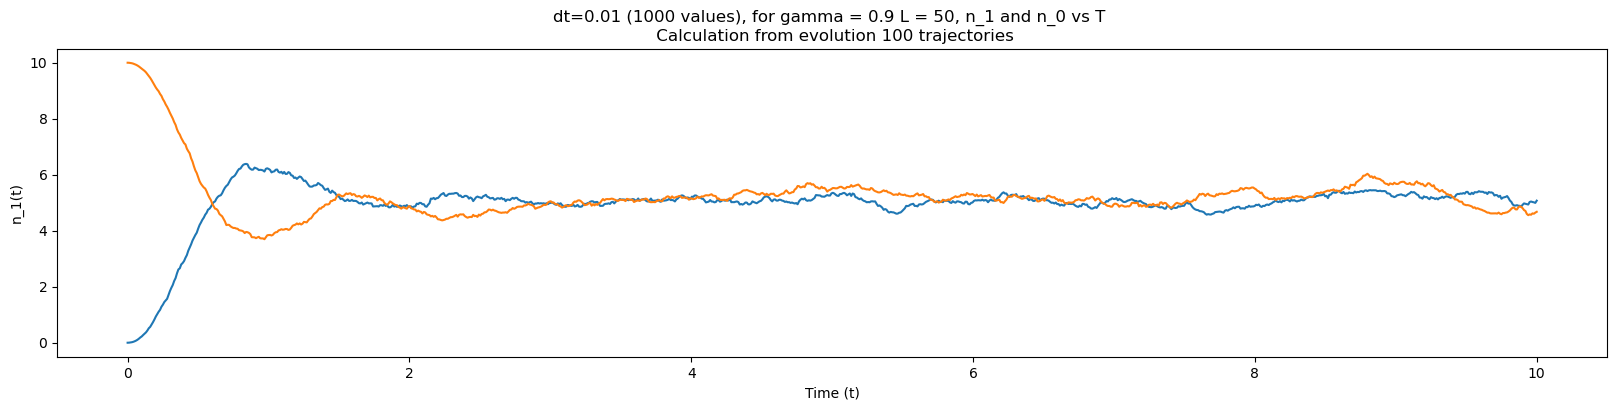

In [50]:
for i in range(10):
    plt.figure(figsize=(20, 4))
    n_1n_2(100,gamma[i],50)
    



100%|██████████| 100/100 [00:00<00:00, 417.08it/s]


Text(0.5, 1.0, '$\\gamma =0 $ n=0 and n=1 site plot')

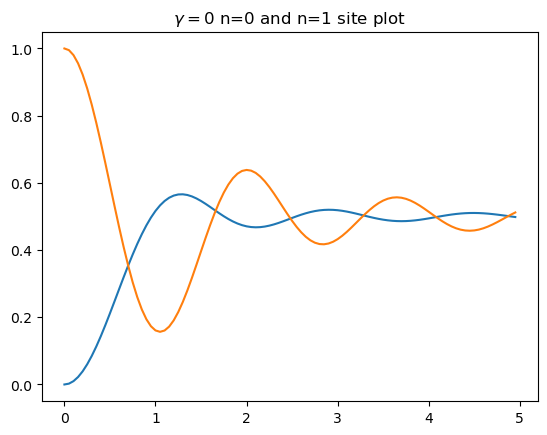

In [267]:
time = np.arange(0,100,1)
n_1= np.zeros((2,len(time)))

U=initial(50)
for t in tqdm(range(len(time))):
    U ,n_1[0,t],n_1[1,t]= evolution(U,H(50),0,0.05)

plt.plot(0.05*time,n_1[0,:])
plt.plot(0.05*time,n_1[1,:])
plt.title("$\gamma =0 $ n=0 and n=1 site plot")

In [ ]:
U=initial(100)
for t in tqdm(range(len(time))):    
    U ,n_1[i,t],n_2[i,t]= evolution(U,H(100),gamma[i],0.05)

In [165]:
corr1 = np.zeros((10,1000))

In [149]:
corr1

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [331]:
def corr(U2,t,i):
    U3=U2
    sum = 0
    D = np.dot(U3,U3.conjugate().T)
    nj= np.diag(D).real
    for k in range(25):
        for k1 in range(25):
            sum = (sum + (U3.conjugate()[1,k1]*U3[1,k]*U3.conjugate()[1,k]*U3[1,k1])*(nj[k]-nj[k]*nj[k1])).real
    
    corr1[t,i]= sum

In [304]:
corr1 = np.zeros((10,1000))

In [1]:
U = initial(50)
U

NameError: name 'initial' is not defined

In [324]:
def prop(time,gamma):
    
    for t1 in range(10):        
        U = initial(50)
        
        for t in range(time):
            U = evolution(U,H(50),gamma,0.01)[0]
                

        U2 = U
        
        for i in range(1000):    
            corr(U2,t1,i)
            U2 = evolution(U2,H(50),gamma,0.005)[0]


            
    return  np.sum(corr1, axis=0)/10

    

In [332]:

corr1 = np.zeros((10,1000))
multicor = prop(i+1,0)

Text(0.5, 1.0, '1000 steps dt =0.005 gamma = 0')

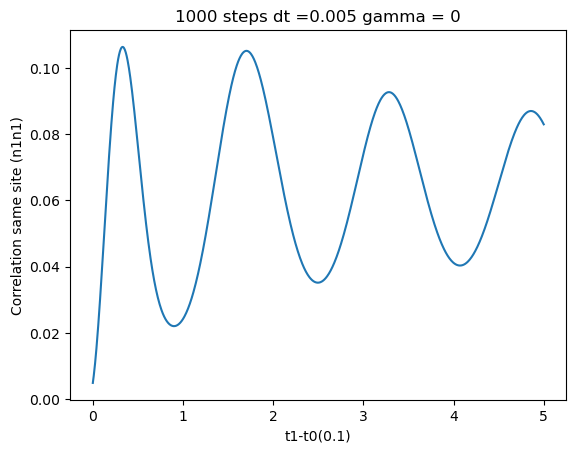

In [333]:
time = np.linspace(0,5,1000)
plt.plot(time,multicor)

plt.xlabel('t1-t0(0.1)')
plt.ylabel('Correlation same site (n1n1)')
plt.title('1000 steps dt =0.005 gamma = 0')

In [236]:
multicor2= np.zeros((50,1000))
for i in tqdm(range(50)):
    corr1 = np.zeros((10,1000))
    multicor2[i] = prop(i+1,0.2)

multicor3= np.zeros((50,1000))
for i in tqdm(range(50)):
    corr1 = np.zeros((10,1000))
    multicor3[i] = prop(i+1,0.3)

multicor4= np.zeros((50,1000))
for i in tqdm(range(50)):
    corr1 = np.zeros((10,1000))
    multicor4[i] = prop(i+1,0.4)

multicor5= np.zeros((50,1000))
for i in tqdm(range(50)):
    corr1 = np.zeros((10,1000))
    multicor5[i] = prop(i+1,0.5)

multicor6= np.zeros((50,1000))
for i in tqdm(range(50)):
    corr1 = np.zeros((10,1000))
    multicor6[i] = prop(i+1,0.6)






100%|██████████| 50/50 [34:38<00:00, 41.56s/it]


In [226]:
multicor

array([[0.65662917, 0.03147318, 0.53437977, ..., 0.99204472, 0.99844689,
        0.69196191],
       [0.75345498, 0.43172024, 0.97766611, ..., 0.94495935, 0.73287148,
        0.82522733],
       [0.86227453, 0.7001298 , 0.87408903, ..., 0.66356069, 0.23186962,
        0.59403562],
       ...,
       [0.80539158, 0.03315248, 0.48149597, ..., 0.3393373 , 0.387477  ,
        0.38264048],
       [0.09701525, 0.21122906, 0.11463983, ..., 0.79709015, 0.32914195,
        0.69969285],
       [0.68101612, 0.99298283, 0.79812133, ..., 0.27143563, 0.97578525,
        0.77524326]])

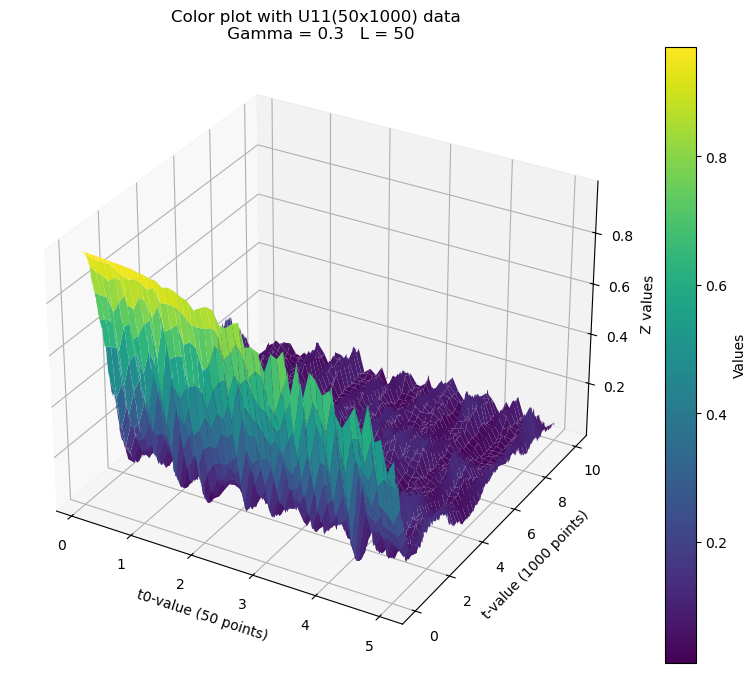

In [252]:

# Create the meshgrid for X and Y
x = np.linspace(0.1, 5, 50)  # X-axis (50 points)
y = np.linspace(0, 10, 1000)  # Y-axis (1000 points)
X, Y = np.meshgrid(x, y)  # Create the grid for 3D plotting

# Transpose multicor to match the dimensions of X and Y
Z = multicor5.T  # Z values (1000x50)

# Create the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
surf = ax.plot_surface(X, Y, Z, cmap='viridis')

# Add colorbar for the surface plot
fig.colorbar(surf, ax=ax, label='Values')

# Labels and title
ax.set_xlabel('t0-value (50 points)')
ax.set_ylabel('t-value (1000 points)')
ax.set_zlabel('Z values')
ax.set_title('Color plot with U11(50x1000) data \n Gamma = 0.3   L = 50')

plt.show()

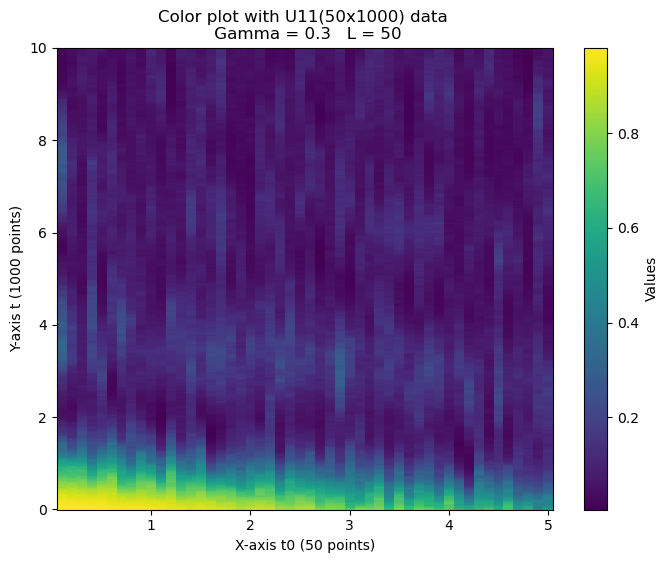

In [265]:
plt.figure(figsize=(8, 6))
mesh = plt.pcolormesh(np.linspace(0.1, 5, 50),np.linspace(0, 10, 1000),  multicor5.T, shading='auto', cmap='viridis')

# Add colorbar to indicate the value range
plt.colorbar(mesh, label='Values')

# Labels and title
plt.xlabel('X-axis t0 (50 points)')
plt.ylabel('Y-axis t (1000 points)')
plt.title('Color plot with U11(50x1000) data \n Gamma = 0.3   L = 50')

plt.show()

In [223]:
multicor.shape

(50, 1000)

In [123]:
for t1 in range(10):
    U = initial(50)
    for t in range(10):
        U = evolution(U,H(50),0,0.01)[0]
        

    U2 = U
    
    for i in range(1000):    
        corr(U2,t1,i)
        U2 = evolution(U2,H(50),0,0.005)[0]

In [124]:
for i in range(1000):    
    corr(U2,i)
    U2 = evolution(U2,H(50),0,0.01)[0]


In [ ]:
U = initial(50)
for t in range(10):
    U = evolution(U,H(50),0,0.01)[0]
     
sum = 0
for k in range(25):
    for k1 in range(25):
        sum = (sum + U.conjugate()[1,k1]*U[1,k]*U.conjugate()[1,k]*U[1,k1]).real


U2 = U

array([0.9607903 , 0.95676161, 0.95236377, ..., 0.02289368, 0.02234358,
       0.        ])

Text(0.5, 1.0, '1000 steps dt =0.005 gamma = 0.6')

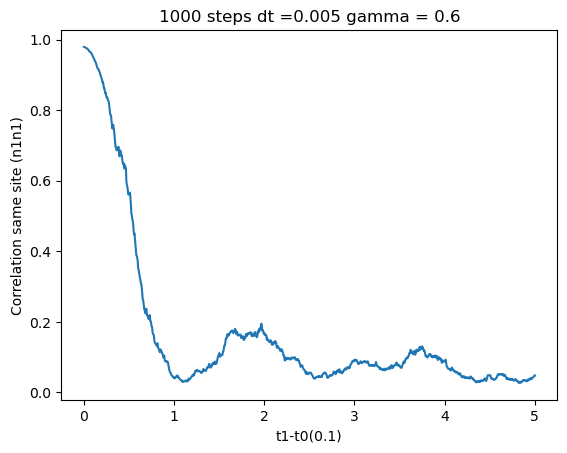

In [275]:
time = np.linspace(0,5,1000)
plt.plot(time,multicor5[1])

plt.xlabel('t1-t0(0.1)')
plt.ylabel('Correlation same site (n1n1)')
plt.title('1000 steps dt =0.005 gamma = 0.6')

In [291]:
corr1

array([0.35467801, 0.03648557, 0.03648557, 0.03648557, 0.03648557,
       0.03648557, 0.03648557, 0.03648557, 0.03648557, 0.03648557])

In [266]:
sum

0.35467800706129005

In [7]:
A = np.array([[1+1j,2+1j],[3+1j,4+1j]])
print(A)
print(A.conj())
print(A.T)
print(A.conj().T)

[[1.+1.j 2.+1.j]
 [3.+1.j 4.+1.j]]
[[1.-1.j 2.-1.j]
 [3.-1.j 4.-1.j]]
[[1.+1.j 3.+1.j]
 [2.+1.j 4.+1.j]]
[[1.-1.j 3.-1.j]
 [2.-1.j 4.-1.j]]
